<a href="https://colab.research.google.com/github/lucas-estanislau/pe-de-meia/blob/main/02_agrega%C3%A7%C3%A3o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from google.colab import drive
import os

In [ ]:
# Concatena todos os meses de todos os anos em um único dataframe
anos = [2024, 2025, 2026]
dfs = []
caminho = "/content/drive/MyDrive/pe-de-meia/pe-de-meia-data"

for ano in anos:
    pasta_ano = os.path.join(caminho, str(ano))

    for arquivo in sorted(os.listdir(pasta_ano)):
        if arquivo.endswith(".csv"):
            caminho_arquivo = os.path.join(pasta_ano, arquivo)

            df = pd.read_csv(caminho_arquivo)
            df["ANO"] = ano
            dfs.append(df)

            print(f"{ano} - {arquivo} carregado!")

df_final = pd.concat(dfs, ignore_index=True)

2024 - abr24_uf.csv carregado!
2024 - ago24_uf.csv carregado!
2024 - dez24_uf.csv carregado!
2024 - jun24_uf.csv carregado!
2024 - mai24_uf.csv carregado!
2024 - mar24_uf.csv carregado!
2024 - nov24_uf.csv carregado!
2024 - out24_uf.csv carregado!
2024 - set24_uf.csv carregado!
2025 - abr25_uf.csv carregado!
2025 - ago25_uf.csv carregado!
2025 - dez25_uf.csv carregado!
2025 - fev25_uf.csv carregado!
2025 - jan25_uf.csv carregado!
2025 - jul25_uf.csv carregado!
2025 - jun25_uf.csv carregado!
2025 - mai25_uf.csv carregado!
2025 - mar25_uf.csv carregado!
2025 - nov25_uf.csv carregado!
2025 - out25_uf.csv carregado!
2025 - set25_uf.csv carregado!
2026 - abr26_uf.csv carregado!
2026 - fev26_uf.csv carregado!
2026 - jun26_uf.csv carregado!
2026 - mai26_uf.csv carregado!
2026 - mar26_uf.csv carregado!


In [ ]:
df_final

,UF,TIPO INCENTIVO,VALOR_TOTAL,QUANTIDADE_PAGAMENTOS,ANO
0,AC,Frequência,3133200.0,15666,2024
1,AC,Matrícula,1839800.0,9199,2024
2,AL,Frequência,13613400.0,68067,2024
3,AL,Matrícula,272000.0,1360,2024
4,AM,Frequência,17360600.0,86803,2024
...,...,...,...,...,...
2100,SP,Matrícula,99670200.0,498351,2026
2101,TO,Conclusão,5095000.0,5095,2026
2102,TO,Enem,563400.0,2817,2026
2103,TO,Frequência,9800.0,49,2026


In [ ]:
# Realiza a operação de soma para cada tipo de incentivo para cada UF
df_pdm_anual = (
    df_final
    .groupby(
        ["ANO", "UF", "TIPO INCENTIVO"],
        as_index=False
    )
    .agg(
        VALOR_TOTAL=("VALOR_TOTAL", "sum"),
        QUANTIDADE_PAGAMENTOS=("QUANTIDADE_PAGAMENTOS", "sum")
    )
)

df_pdm_anual = df_pdm_anual.sort_values(
    ["ANO", "UF", "TIPO INCENTIVO"]
).reset_index(drop=True)

display(df_pdm_anual.head())

,ANO,UF,TIPO INCENTIVO,VALOR_TOTAL,QUANTIDADE_PAGAMENTOS
0,2024,AC,Frequência,33242625.0,165877
1,2024,AC,Matrícula,5205400.0,26027
2,2024,AL,Frequência,126806125.0,631927
3,2024,AL,Matrícula,19438600.0,97193
4,2024,AM,Frequência,128097525.0,639118


In [ ]:
df_pdm_anual

,ANO,UF,TIPO INCENTIVO,VALOR_TOTAL,QUANTIDADE_PAGAMENTOS
0,2024,AC,Frequência,33242625.0,165877
1,2024,AC,Matrícula,5205400.0,26027
2,2024,AL,Frequência,126806125.0,631927
3,2024,AL,Matrícula,19438600.0,97193
4,2024,AM,Frequência,128097525.0,639118
...,...,...,...,...,...
265,2026,SP,Matrícula,106481200.0,532406
266,2026,TO,Conclusão,32088000.0,38544
267,2026,TO,Enem,974200.0,4871
268,2026,TO,Frequência,22019475.0,109859


In [ ]:
# Salva o dataframe com todos os anos, meses, UFs e tipo de incentivo
df_pdm_anual.to_csv(
            f"/content/drive/MyDrive/pe-de-meia/agregados/pe-de-meia-2024-2026.csv",
            index=False
        )

In [ ]:
# Agrupa o valor total de pagamentos por ano em cada UF, independente do tipo de incentivo
df_valor_total = df_pdm_anual.groupby(["ANO", "UF"], as_index=False).agg(
        VALOR_TOTAL=("VALOR_TOTAL", "sum"),
        QUANTIDADE_PAGAMENTOS=("QUANTIDADE_PAGAMENTOS", "sum")
    )

In [ ]:
df_valor_total

,ANO,UF,VALOR_TOTAL,QUANTIDADE_PAGAMENTOS
0,2024,AC,38448025.0,191904
1,2024,AL,146244725.0,729120
2,2024,AM,155529925.0,776280
3,2024,AP,36293675.0,181301
4,2024,BA,605883725.0,3018872
...,...,...,...,...
76,2026,RS,171764575.0,512329
77,2026,SC,85720950.0,265445
78,2026,SE,103432000.0,301014
79,2026,SP,782836450.0,2160228


In [ ]:
# Verificando se há 27 estados para cada ano para evitar dado perdido
df_valor_total.groupby("ANO").size()

,0
ANO,
2024,27
2025,27
2026,27


In [ ]:
# Salva o dataframe agrupado por ano com valor total para cada UF
df_valor_total.to_csv(
            f"/content/drive/MyDrive/pe-de-meia/agregados/pe-de-meia-2024-2026-total-UF.csv",
            index=False
        )

## Dados INEP

In [ ]:
caminho = "/content/drive/MyDrive/pe-de-meia/inep/inep-data/taxas_em_uf_2007_2025.csv"

df_inep = pd.read_csv(caminho)

In [ ]:
print("Anos disponíveis no INEP:")
print(df_inep.groupby("ANO").size())

print("\nRegistros de 2024 e 2025:")
display(df_inep[df_inep["ANO"].isin([2024, 2025])].head())

print("\nTipos das chaves:")
print(df_inep[["ANO", "UF"]].dtypes)
print(df_valor_total[["ANO", "UF"]].dtypes)

print("\nUFs do INEP:")
print(df_inep["UF"].unique())

Anos disponíveis no INEP:
ANO
2007    27
2008    27
2009    27
2010    27
2011    27
2012    27
2013    27
2014    27
2015    27
2016    27
2017    27
2018    27
2019    27
2020    27
2021    27
2022    27
2023    27
2024    27
2025    27
dtype: int64

Registros de 2024 e 2025:


,ANO,UF,TAXA_APROVACAO,TAXA_REPROVACAO,TAXA_ABANDONO
459,2024,AC,86.8,8.2,5.0
460,2024,AL,90.2,5.7,4.1
461,2024,AM,89.2,6.5,4.3
462,2024,AP,88.0,8.1,3.9
463,2024,BA,88.4,5.1,6.5



Tipos das chaves:
ANO     int64
UF     object
dtype: object
ANO     int64
UF     object
dtype: object

UFs do INEP:
['AC' 'AL' 'AM' 'AP' 'BA' 'CE' 'DF' 'ES' 'GO' 'MA' 'MG' 'MS' 'MT' 'PA'
 'PB' 'PE' 'PI' 'PR' 'RJ' 'RN' 'RO' 'RR' 'RS' 'SC' 'SE' 'SP' 'TO']


## Juntando os dados do Pé-De-Meia com os do as taxas de rendimento do INEP

In [ ]:
df_final = pd.merge(
    df_valor_total,
    df_inep,
    on=["ANO", "UF"],
    how="left",
    validate="one_to_one",
    indicator=True
)

display(df_final.head())

,ANO,UF,VALOR_TOTAL,QUANTIDADE_PAGAMENTOS,TAXA_APROVACAO,TAXA_REPROVACAO,TAXA_ABANDONO,_merge
0,2024,AC,38448025.0,191904,86.8,8.2,5.0,both
1,2024,AL,146244725.0,729120,90.2,5.7,4.1,both
2,2024,AM,155529925.0,776280,89.2,6.5,4.3,both
3,2024,AP,36293675.0,181301,88.0,8.1,3.9,both
4,2024,BA,605883725.0,3018872,88.4,5.1,6.5,both


In [ ]:
df_final

,ANO,UF,VALOR_TOTAL,QUANTIDADE_PAGAMENTOS,TAXA_APROVACAO,TAXA_REPROVACAO,TAXA_ABANDONO,_merge
0,2024,AC,38448025.0,191904,86.8,8.2,5.0,both
1,2024,AL,146244725.0,729120,90.2,5.7,4.1,both
2,2024,AM,155529925.0,776280,89.2,6.5,4.3,both
3,2024,AP,36293675.0,181301,88.0,8.1,3.9,both
4,2024,BA,605883725.0,3018872,88.4,5.1,6.5,both
...,...,...,...,...,...,...,...,...
76,2026,RS,171764575.0,512329,NaN,NaN,NaN,left_only
77,2026,SC,85720950.0,265445,NaN,NaN,NaN,left_only
78,2026,SE,103432000.0,301014,NaN,NaN,NaN,left_only
79,2026,SP,782836450.0,2160228,NaN,NaN,NaN,left_only


In [ ]:
df_final.groupby(["ANO", "_merge"], observed=True).size()

,,0
ANO,_merge,
2024,both,27
2025,both,27
2026,left_only,27


In [ ]:
df_final[df_final["ANO"].isin([2024, 2025])]["_merge"].value_counts()

,count
_merge,
both,54
left_only,0
right_only,0


Como no momento da realização desta analise ainda não há dados de taxas de rendimento para o ano de 2026, a coluna "_merge" para o ano de 2026 contém "left_only", pois só há dados do pé-de-meia.

In [ ]:
# Dataframe para analisar somente os anos de 2024 e 2025
df_analise = (
    df_final[df_final["_merge"] == "both"]
    .drop(columns="_merge")
    .copy()
)

In [ ]:
# Salva o dataframe com a junção dos dados do Pé-de-Meia e taxas de rendimento de 2024 e 2025
df_analise.to_csv(
            f"/content/drive/MyDrive/pe-de-meia/agregados/pdm-tx-rendimento-2024-2025.csv",
            index=False
        )

In [ ]:

import pandas as pd
from google.colab import drive

# Conecta ao Drive, caso ainda não esteja conectado
drive.mount("/content/drive")

# Carrega a base final integrada
caminho = "/content/drive/MyDrive/pe-de-meia/agregados/pdm-tx-rendimento-2024-2025.csv"

df_final = pd.read_csv(caminho)

# Confere a estrutura da base
display(df_final.head())
print("Dimensões:", df_final.shape)
print("Colunas:", df_final.columns.tolist())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,ANO,UF,VALOR_TOTAL,QUANTIDADE_PAGAMENTOS,TAXA_APROVACAO,TAXA_REPROVACAO,TAXA_ABANDONO
0,2024,AC,38448025.0,191904,86.8,8.2,5.0
1,2024,AL,146244725.0,729120,90.2,5.7,4.1
2,2024,AM,155529925.0,776280,89.2,6.5,4.3
3,2024,AP,36293675.0,181301,88.0,8.1,3.9
4,2024,BA,605883725.0,3018872,88.4,5.1,6.5


Dimensões: (54, 7)
Colunas: ['ANO', 'UF', 'VALOR_TOTAL', 'QUANTIDADE_PAGAMENTOS', 'TAXA_APROVACAO', 'TAXA_REPROVACAO', 'TAXA_ABANDONO']


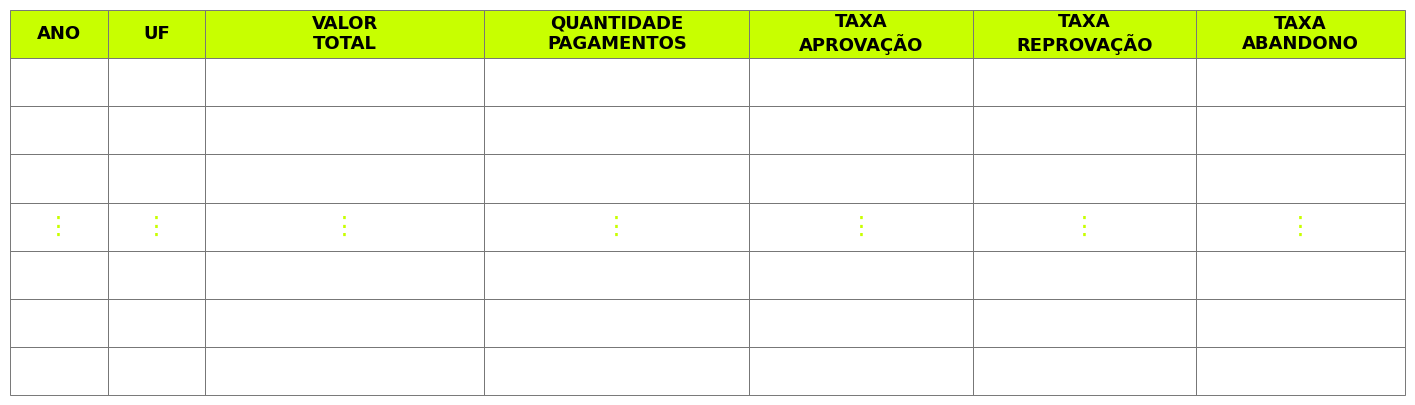

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Carregar base integrada
caminho = "/content/drive/MyDrive/pe-de-meia/agregados/pdm-tx-rendimento-2024-2025.csv"
df_final = pd.read_csv(caminho)

colunas = [
    "ANO", "UF", "VALOR_TOTAL",
    "QUANTIDADE_PAGAMENTOS",
    "TAXA_APROVACAO",
    "TAXA_REPROVACAO",
    "TAXA_ABANDONO"
]

df = df_final[colunas].copy()
df["ANO"] = pd.to_numeric(df["ANO"])
df = df.sort_values(["ANO", "UF"])

# Três registros de 2024 e três de 2025
inicio = df[df["ANO"] == 2024].head(3)
fim = df[df["ANO"] == 2025].tail(3)

if inicio.empty or fim.empty:
    raise ValueError("Registros de 2024 ou 2025 não encontrados.")

# Formatação dos valores
def formatar(coluna, valor):
    if pd.isna(valor):
        return "—"
    if coluna == "ANO":
        return str(int(valor))
    if coluna == "VALOR_TOTAL":
        return "R$ " + f"{float(valor):,.0f}".replace(",", ".")
    if coluna == "QUANTIDADE_PAGAMENTOS":
        return f"{int(valor):,}".replace(",", ".")
    if coluna.startswith("TAXA_"):
        return f"{float(valor):.1f}".replace(".", ",") + "%"
    return str(valor)

def preparar(dados):
    return pd.DataFrame({
        c: dados[c].map(lambda v: formatar(c, v))
        for c in colunas
    })

reticencias = pd.DataFrame(
    [["⋮"] * len(colunas)],
    columns=colunas
)

amostra = pd.concat(
    [preparar(inicio), reticencias, preparar(fim)],
    ignore_index=True
)

# Cores da apresentação
VERDE = "#C8FF00"
BRANCO = "#FFFFFF"
TRANSPARENTE = (0, 0, 0, 0)

cabecalhos = [
    "ANO",
    "UF",
    "VALOR\nTOTAL",
    "QUANTIDADE\nPAGAMENTOS",
    "TAXA\nAPROVAÇÃO",
    "TAXA\nREPROVAÇÃO",
    "TAXA\nABANDONO"
]

# Criar tabela
fig, ax = plt.subplots(figsize=(18, 5))
fig.patch.set_alpha(0)
ax.axis("off")

tabela = ax.table(
    cellText=amostra.values,
    colLabels=cabecalhos,
    colWidths=[0.07, 0.07, 0.20, 0.19, 0.16, 0.16, 0.15],
    cellLoc="center",
    colLoc="center",
    bbox=[0, 0, 1, 1]
)

tabela.auto_set_font_size(False)
tabela.set_fontsize(13)

for (linha, coluna), celula in tabela.get_celld().items():
    celula.set_edgecolor("#777777")
    celula.set_linewidth(0.7)

    if linha == 0:
        celula.set_facecolor(VERDE)
        celula.get_text().set_color("#000000")
        celula.get_text().set_weight("bold")
    else:
        celula.set_facecolor(TRANSPARENTE)
        celula.get_text().set_color(BRANCO)

    if linha == 4:
        celula.get_text().set_color(VERDE)
        celula.get_text().set_fontsize(18)

# Salvar e baixar PNG
arquivo = "base_integrada_pdm_inep.png"

plt.savefig(
    arquivo,
    dpi=300,
    transparent=True,
    bbox_inches="tight",
    pad_inches=0.05
)

plt.show()
files.download(arquivo)
